DELTA CPU Energy

Rata-rata EC per Versi (mJ):


,Versi,EC_CPU (mJ)
0,P1,0.466464
1,P2,0.466464
2,P3,0.466464
3,P4,0.466464
4,P5,0.466464


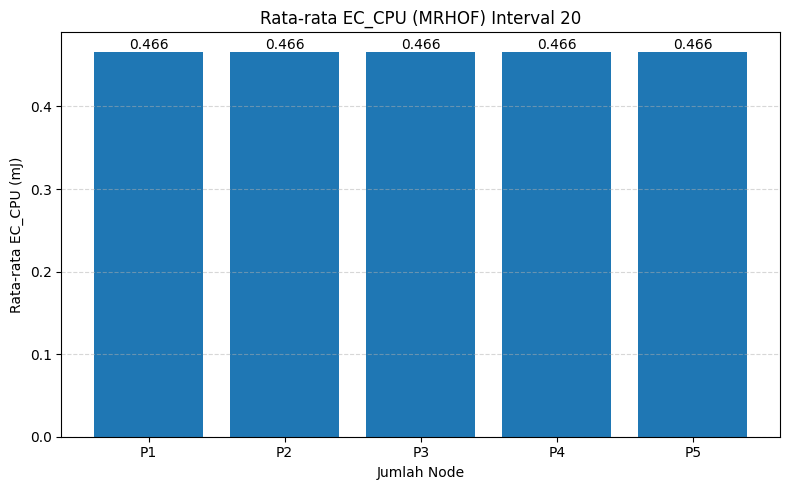

CSV tersimpan di: /content/ec_mrhof_output


In [ ]:
# === MRHOF EC (DELTA_CPU_LOG) Parser & Plot — fix mJ ===
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# 1) Path CSV per skenario (sesuaikan)
file_paths = {
     "P1": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval301.csv",
    "P2": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval302.csv",
    "P3": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval303.csv",
      "P4": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval304.csv",
      "P5": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval305.csv",
}

# 2) Regex DELTA_CPU_LOG (unit fix mJ → tanpa konversi)
pattern = re.compile(
    r"DELTA_CPU_LOG:\s*Node\s*=\s*(\d+).*?EC_CPU\s*=\s*([\d.]+)\s*mJ",
    flags=re.IGNORECASE
)

# 3) Ekstraksi EC_CPU (mJ) ke DataFrame
rows = []
for versi, path in file_paths.items():
    if not path or not Path(path).exists():
        print(f"[LEWATI] File tidak ditemukan: {path}")
        continue

    df = pd.read_csv(path)
    msg_col = "message" if "message" in df.columns else df.columns[-1]

    for _, r in df.iterrows():
        msg = str(r.get(msg_col, ""))
        m = pattern.search(msg)
        if m:
            node_id = int(m.group(1))
            ec_mj = float(m.group(2))  # langsung mJ
            rows.append({"Versi": versi, "Node": node_id, "EC_CPU (mJ)": ec_mj})

df_ec = pd.DataFrame(rows)

if df_ec.empty:
    raise ValueError("Tidak ada baris DELTA_CPU_LOG (mJ) yang terdeteksi. Cek path/format log.")

# 4) Rata-rata per Versi (agregat lintas node & waktu)
avg_ec_per_versi = (
    df_ec.groupby("Versi", as_index=False)["EC_CPU (mJ)"].mean().sort_values("Versi")
)

# (Opsional) Rata-rata per Node per Versi
avg_ec_per_node = (
    df_ec.groupby(["Versi", "Node"], as_index=False)["EC_CPU (mJ)"].mean()
)

print("Rata-rata EC per Versi (mJ):")
display(avg_ec_per_versi)

# 5) Visualisasi: Bar chart rata-rata EC per Versi
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_ec_per_versi["Versi"], avg_ec_per_versi["EC_CPU (mJ)"])

# Tampilkan nilai di atas batang
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h, f"{h:.3f}", ha="center", va="bottom")

plt.xlabel("Jumlah Node")
plt.ylabel("Rata-rata EC_CPU (mJ)")
plt.title("Rata-rata EC_CPU (MRHOF) Interval 20")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 6) Simpan rekap ke CSV (opsional)
out_dir = Path("./ec_mrhof_output")
out_dir.mkdir(parents=True, exist_ok=True)
avg_ec_per_versi.to_csv(out_dir / "avg_ec_per_versi.csv", index=False)
avg_ec_per_node.to_csv(out_dir / "avg_ec_per_node.csv", index=False)
print(f"CSV tersimpan di: {out_dir.resolve()}")


Control Over Head

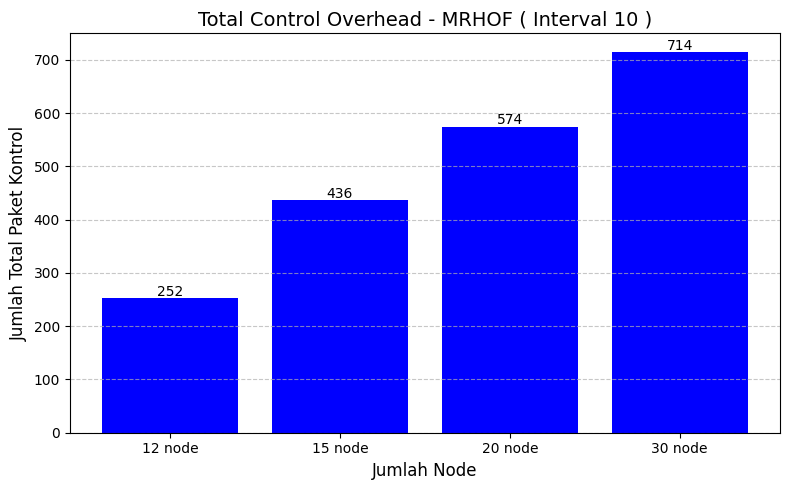

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# === STEP 1: Daftar file versi log MMDEW ===
file_paths = {
     "12 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/12node20.csv",
    "15 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/15node20.csv",
    "20 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/20node20.csv",
      "30 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/30node20.csv",


}

# === STEP 2: Regex pola untuk pesan kontrol DIS, DIO, DAO ===
patterns = {
    "DIS": re.compile(r"Tx DIS"),
    "DIO": re.compile(r"Tx DIO"),
    "DAO": re.compile(r"Tx DAO"),
}

# === STEP 3: Hitung jumlah COH untuk tiap versi ===
coh_data = []

for version, path in file_paths.items():
    df = pd.read_csv(path)
    messages = df['message'].dropna()

    dis_count = messages.str.contains(patterns["DIS"]).sum()
    dio_count = messages.str.contains(patterns["DIO"]).sum()
    dao_count = messages.str.contains(patterns["DAO"]).sum()
    total = dis_count + dio_count + dao_count

    coh_data.append({
        "Versi": version,
        "DIS": dis_count,
        "DIO": dio_count,
        "DAO": dao_count,
        "Total COH": total
    })

# Konversi ke DataFrame
df_coh = pd.DataFrame(coh_data)

# === STEP 4: Visualisasi total Control Overhead ===
plt.figure(figsize=(8, 5))
bars = plt.bar(df_coh["Versi"], df_coh["Total COH"], color='blue')

# Label nilai di atas batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 5, f'{height}', ha='center', fontsize=10)

plt.title("Total Control Overhead - MRHOF ( Interval 10 )", fontsize=14)
plt.xlabel("Jumlah Node", fontsize=12)
plt.ylabel("Jumlah Total Paket Kontrol", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


PDR MRHOF

Rata-rata FINAL PDR per Versi (%):


,Versi,PDR (%)
0,P1,68.0
1,P2,68.0
2,P3,66.0
3,P4,68.0
4,P5,66.0


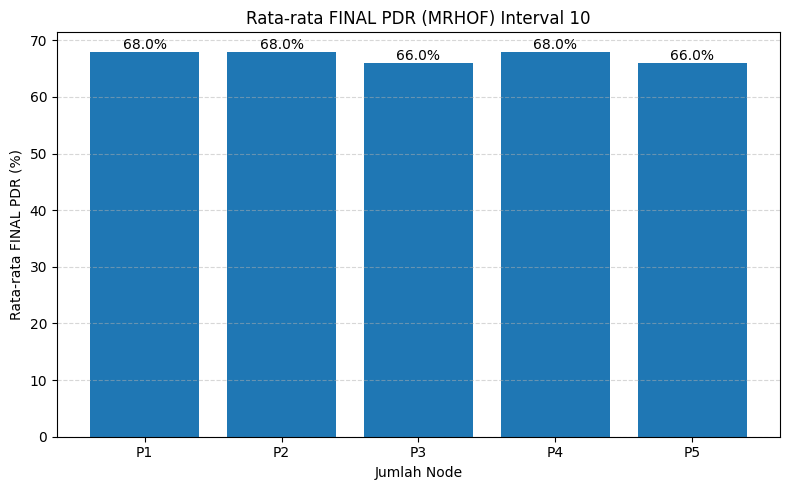

CSV tersimpan di: /content/pdr_mrhof_output


In [1]:
# === MRHOF FINAL PDR Parser & Plot ===
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# 1) Path CSV per skenario (sesuaikan)
file_paths = {
  "P1": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility5/MRHOF/20/MRHOFmob5Interval201.csv",
    "P2": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility5/MRHOF/20/MRHOFmob5Interval202.csv",
    "P3": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility5/MRHOF/20/MRHOFmob5Interval203.csv",
      "P4": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility5/MRHOF/20/MRHOFmob5Interval204.csv",
      "P5": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility5/MRHOF/20/MRHOFmob5Interval205.csv",
}

# 2) Regex untuk baris FINAL PDR
#    Menangkap Received, Lost, dan PDR% (angka saja). Fleksibel terhadap spasi.
pdr_pattern = re.compile(
    r"FINAL\s+PDR:\s*Received\s*=\s*(\d+)\s*,\s*Lost\s*=\s*(\d+)\s*,\s*PDR\s*=\s*(\d+)\s*%",
    flags=re.IGNORECASE
)

# 3) Ekstraksi FINAL PDR ke DataFrame
rows = []
for versi, path in file_paths.items():
    if not path or not Path(path).exists():
        print(f"[LEWATI] File tidak ditemukan: {path}")
        continue

    df = pd.read_csv(path)

    # Deteksi nama kolom yang berisi pesan log
    msg_col = "message" if "message" in df.columns else df.columns[-1]
    # (Opsional) deteksi kolom node/id
    node_col = None
    for c in df.columns:
        if c.lower() in ("node", "id", "mote", "source", "src"):
            node_col = c
            break

    for _, r in df.iterrows():
        msg = str(r.get(msg_col, ""))
        m = pdr_pattern.search(msg)
        if m:
            received = int(m.group(1))
            lost     = int(m.group(2))
            pdr_pct  = float(m.group(3))  # sudah persen (0-100)
            rows.append({
                "Versi": versi,
                "Node": r.get(node_col) if node_col in r else None,
                "Received": received,
                "Lost": lost,
                "PDR (%)": pdr_pct
            })

df_pdr = pd.DataFrame(rows)

if df_pdr.empty:
    raise ValueError("Tidak ditemukan baris 'FINAL PDR' pada file-file yang diberikan. Cek path/format log.")

# 4) Rekap: rata-rata PDR per Versi
avg_pdr_per_versi = (
    df_pdr.groupby("Versi", as_index=False)["PDR (%)"].mean().sort_values("Versi")
)

# (Opsional) Rekap per Node per Versi
avg_pdr_per_node = (
    df_pdr.groupby(["Versi", "Node"], as_index=False)["PDR (%)"].mean()
)

print("Rata-rata FINAL PDR per Versi (%):")
display(avg_pdr_per_versi)

# 5) Visualisasi: Bar chart rata-rata FINAL PDR per Versi
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_pdr_per_versi["Versi"], avg_pdr_per_versi["PDR (%)"])

# Tampilkan nilai di atas batang
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h, f"{h:.1f}%", ha="center", va="bottom")

plt.xlabel("Jumlah Node")
plt.ylabel("Rata-rata FINAL PDR (%)")
plt.title("Rata-rata FINAL PDR (MRHOF) Interval 10")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 6) Simpan rekap ke CSV (opsional)
out_dir = Path("./pdr_mrhof_output")
out_dir.mkdir(parents=True, exist_ok=True)
avg_pdr_per_versi.to_csv(out_dir / "avg_pdr_per_versi.csv", index=False)
avg_pdr_per_node.to_csv(out_dir / "avg_pdr_per_node.csv", index=False)
print(f"CSV tersimpan di: {out_dir.resolve()}")


End-to-End Delay

Rata-rata Delay per Versi (ms):


,Versi,Delay (ms)
0,P1,292.747115
1,P2,287.346320
2,P3,291.011713
3,P4,288.183386
4,P5,290.187527


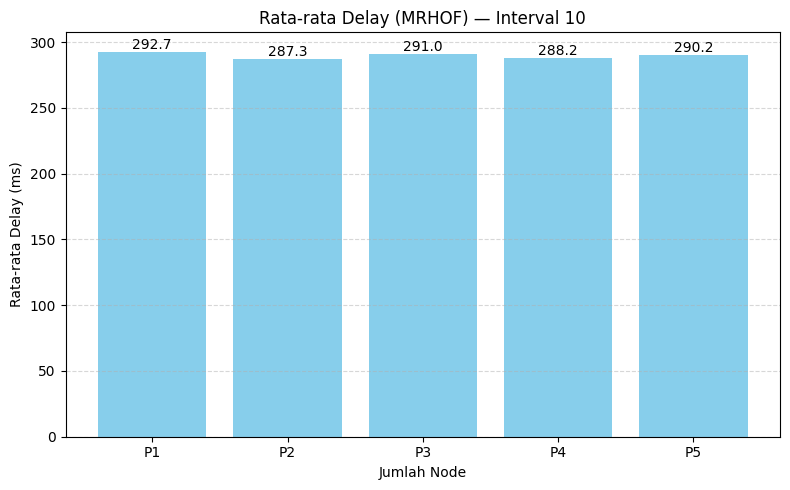

CSV tersimpan di: /content/delay_mrhof_output


In [6]:
# === MRHOF Delay Parser & Plot (Mean only, Outlier Handling) ===
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# 1) Path CSV per skenario (sesuaikan)
file_paths = {
    "P1": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval101.csv",
    "P2": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval102.csv",
    "P3": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval103.csv",
      "P4": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval104.csv",
      "P5": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval105.csv",
}

# 2) Regex Delay=...ms
delay_pattern = re.compile(r"Delay\s*=\s*(\d+)\s*ms", flags=re.IGNORECASE)

# === Parameter outlier ===
HARD_THRESHOLD_MS = 10_000  # buang Delay > 10 detik
USE_IQR = True              # filter outlier dengan IQR

# 3) Ekstraksi Delay
rows = []
for versi, path in file_paths.items():
    if not path or not Path(path).exists():
        print(f"[LEWATI] File tidak ditemukan: {path}")
        continue

    df = pd.read_csv(path)
    msg_col = "message" if "message" in df.columns else df.columns[-1]

    for _, r in df.iterrows():
        msg = str(r.get(msg_col, ""))
        m = delay_pattern.search(msg)
        if m:
            delay_ms = int(m.group(1))
            rows.append({"Versi": versi, "Delay (ms)": delay_ms})

df_delay_raw = pd.DataFrame(rows)
if df_delay_raw.empty:
    raise ValueError("Tidak ditemukan log 'Delay=...ms'.")

# 4) Buang outlier
df_delay = df_delay_raw.copy()

if HARD_THRESHOLD_MS is not None:
    df_delay = df_delay[df_delay["Delay (ms)"] <= HARD_THRESHOLD_MS]

if USE_IQR and not df_delay.empty:
    cleaned_list = []
    for versi, g in df_delay.groupby("Versi"):
        Q1 = g["Delay (ms)"].quantile(0.25)
        Q3 = g["Delay (ms)"].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        cleaned = g[(g["Delay (ms)"] >= lower) & (g["Delay (ms)"] <= upper)]
        cleaned_list.append(cleaned)
    df_delay = pd.concat(cleaned_list, ignore_index=True)

# 5) Hitung rata-rata Delay per Versi
avg_delay_per_versi = (
    df_delay.groupby("Versi", as_index=False)["Delay (ms)"].mean().sort_values("Versi")
)

print("Rata-rata Delay per Versi (ms):")
display(avg_delay_per_versi)

# 6) Visualisasi: Bar chart mean Delay
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_delay_per_versi["Versi"], avg_delay_per_versi["Delay (ms)"], color="skyblue")

for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h, f"{h:.1f}", ha="center", va="bottom")

plt.xlabel("Jumlah Node")
plt.ylabel("Rata-rata Delay (ms)")
plt.title("Rata-rata Delay (MRHOF) — Interval 10")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 7) Simpan CSV (opsional)
out_dir = Path("./delay_mrhof_output")
out_dir.mkdir(parents=True, exist_ok=True)
avg_delay_per_versi.to_csv(out_dir / "delay_summary_mean.csv", index=False)
print(f"CSV tersimpan di: {out_dir.resolve()}")


RSSI

[INFO] Sampel awal: 15610 | Dibuang (threshold): 0 | Dibuang (IQR): 0
Rata-rata RSSI per Versi (dBm):


,Versi,RSSI (dBm)
0,P1,-78.501281
1,P2,-78.501281
2,P3,-78.501281
3,P4,-78.501281
4,P5,-78.501281


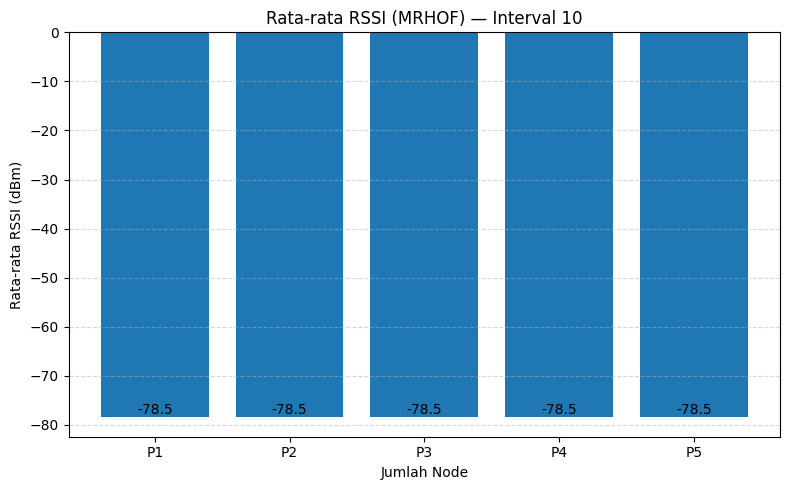

CSV tersimpan di: /content/rssi_mrhof_output


In [ ]:
# === MRHOF RSSI Parser & Plot (Mean only, Outlier Handling) ===
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# 1) Path CSV per skenario (sesuaikan)
file_paths = {
    "P1": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval301.csv",
    "P2": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval302.csv",
    "P3": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval303.csv",
      "P4": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval304.csv",
      "P5": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/2 April/CSV/MRHOF/Mob5/30/MRHOFmob5Interval305.csv",
}

# 2) Regex RSSI=-39dBm (fleksibel spasi, tanda minus, dan desimal)
rssi_pattern = re.compile(r"RSSI\s*=\s*(-?\d+(?:\.\d+)?)\s*dBm", flags=re.IGNORECASE)

# === Parameter outlier ===
# RSSI wajar di WSN biasanya -30 s/d -100 dBm (negatif). Di bawah -120 atau di atas -10 kita anggap anomali.
LOWER_RSSI_DBM  = -120.0
UPPER_RSSI_DBM  = -10.0
USE_IQR = True  # gunakan filter tambahan IQR per versi

# 3) Ekstraksi RSSI mentah
rows = []
for versi, path in file_paths.items():
    if not path or not Path(path).exists():
        print(f"[LEWATI] File tidak ditemukan: {path}")
        continue

    df = pd.read_csv(path)
    msg_col = "message" if "message" in df.columns else df.columns[-1]

    for _, r in df.iterrows():
        msg = str(r.get(msg_col, ""))
        m = rssi_pattern.search(msg)
        if m:
            rssi_dbm = float(m.group(1))
            rows.append({"Versi": versi, "RSSI (dBm)": rssi_dbm})

df_rssi_raw = pd.DataFrame(rows)
if df_rssi_raw.empty:
    raise ValueError("Tidak ditemukan log 'RSSI=...dBm' pada file-file yang diberikan.")

# 4) Buang outlier (threshold + IQR per versi)
# Threshold fisik
df_rssi = df_rssi_raw[(df_rssi_raw["RSSI (dBm)"] >= LOWER_RSSI_DBM) &
                      (df_rssi_raw["RSSI (dBm)"] <= UPPER_RSSI_DBM)].copy()

removed_thresh = len(df_rssi_raw) - len(df_rssi)

# IQR per versi (opsional)
removed_iqr = 0
if USE_IQR and not df_rssi.empty:
    cleaned = []
    for versi, g in df_rssi.groupby("Versi"):
        Q1 = g["RSSI (dBm)"].quantile(0.25)
        Q3 = g["RSSI (dBm)"].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        cg = g[(g["RSSI (dBm)"] >= lower) & (g["RSSI (dBm)"] <= upper)]
        removed_iqr += len(g) - len(cg)
        cleaned.append(cg)
    df_rssi = pd.concat(cleaned, ignore_index=True)

print(f"[INFO] Sampel awal: {len(df_rssi_raw)} | Dibuang (threshold): {removed_thresh} | Dibuang (IQR): {removed_iqr}")
if df_rssi.empty:
    raise ValueError("Semua data RSSI terfilter. Sesuaikan batas threshold/IQR.")

# 5) Rata-rata RSSI per Versi (lebih tinggi = lebih dekat ke 0 = sinyal lebih kuat)
avg_rssi_per_versi = (
    df_rssi.groupby("Versi", as_index=False)["RSSI (dBm)"].mean().sort_values("Versi")
)

print("Rata-rata RSSI per Versi (dBm):")
display(avg_rssi_per_versi)

# 6) Visualisasi: Bar chart mean RSSI
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_rssi_per_versi["Versi"], avg_rssi_per_versi["RSSI (dBm)"])

for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h, f"{h:.1f}", ha="center", va="bottom")

plt.xlabel("Jumlah Node")
plt.ylabel("Rata-rata RSSI (dBm)")
plt.title("Rata-rata RSSI (MRHOF) — Interval 10")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 7) Simpan CSV (opsional)
from pathlib import Path
out_dir = Path("./rssi_mrhof_output")
out_dir.mkdir(parents=True, exist_ok=True)
avg_rssi_per_versi.to_csv(out_dir / "rssi_summary_mean.csv", index=False)
print(f"CSV tersimpan di: {out_dir.resolve()}")


RSSI tanpa Threshold

Rata-rata RSSI per Versi (dBm):


,Versi,RSSI (dBm)
0,12 node,-66.153846
1,15 node,-65.224299
2,20 node,-63.913725
3,30 node,-59.868251


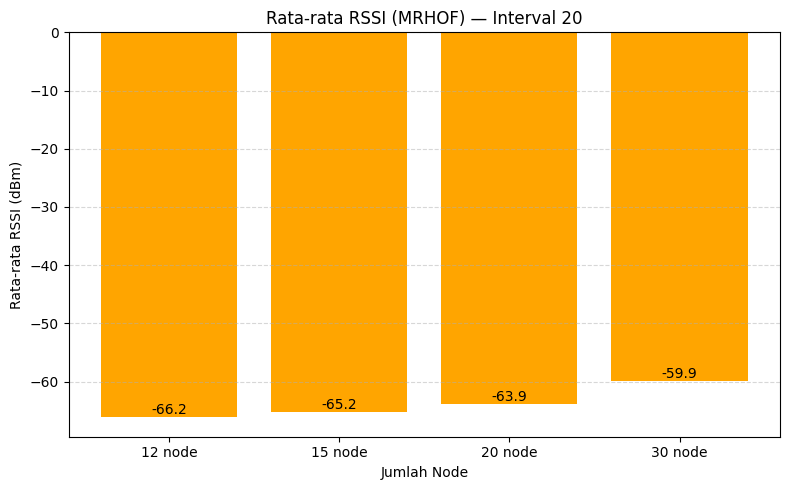

CSV tersimpan di: /content/rssi_mrhof_output


In [ ]:
# === MRHOF RSSI Parser & Plot (Mean only, tanpa threshold/outlier) ===
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# 1) Path CSV per skenario (sesuaikan)
file_paths = {
    "12 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 1/MRHOF 30/12node30asli.csv",
    "15 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 1/MRHOF 30/15node30asli.csv",
    "20 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 1/MRHOF 30/20node30asli.csv",
      "30 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 1/MRHOF 30/30node30asli.csv",
}

# 2) Regex RSSI
rssi_pattern = re.compile(r"RSSI\s*=\s*(-?\d+(?:\.\d+)?)\s*dBm", flags=re.IGNORECASE)

# 3) Ekstraksi RSSI mentah
rows = []
for versi, path in file_paths.items():
    if not path or not Path(path).exists():
        print(f"[LEWATI] File tidak ditemukan: {path}")
        continue

    df = pd.read_csv(path)
    msg_col = "message" if "message" in df.columns else df.columns[-1]

    for _, r in df.iterrows():
        msg = str(r.get(msg_col, ""))
        m = rssi_pattern.search(msg)
        if m:
            rssi_dbm = float(m.group(1))
            rows.append({"Versi": versi, "RSSI (dBm)": rssi_dbm})

df_rssi = pd.DataFrame(rows)
if df_rssi.empty:
    raise ValueError("Tidak ditemukan log 'RSSI=...dBm'.")

# 4) Hitung rata-rata RSSI per Versi
avg_rssi_per_versi = (
    df_rssi.groupby("Versi", as_index=False)["RSSI (dBm)"].mean().sort_values("Versi")
)

print("Rata-rata RSSI per Versi (dBm):")
display(avg_rssi_per_versi)

# 5) Visualisasi: Bar chart mean RSSI
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_rssi_per_versi["Versi"], avg_rssi_per_versi["RSSI (dBm)"], color="orange")

for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h, f"{h:.1f}", ha="center", va="bottom")

plt.xlabel("Jumlah Node")
plt.ylabel("Rata-rata RSSI (dBm)")
plt.title("Rata-rata RSSI (MRHOF) — Interval 20")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 6) Simpan CSV (opsional)
out_dir = Path("./rssi_mrhof_output")
out_dir.mkdir(parents=True, exist_ok=True)
avg_rssi_per_versi.to_csv(out_dir / "rssi_summary_mean_no_filter.csv", index=False)
print(f"CSV tersimpan di: {out_dir.resolve()}")


Handover

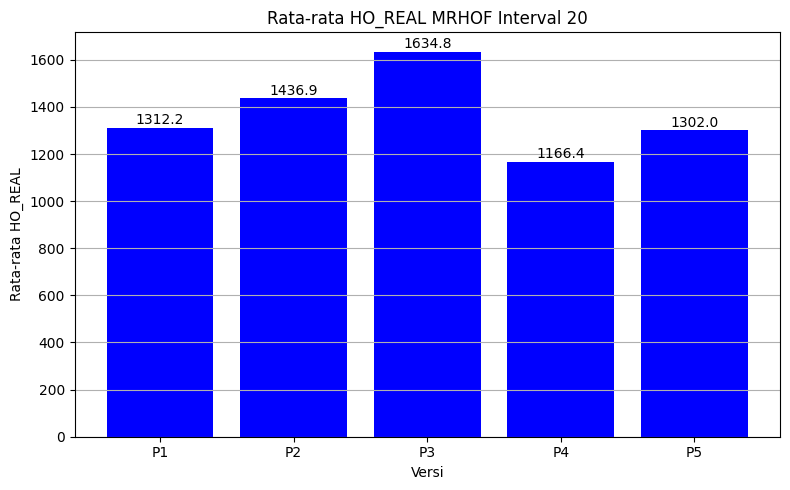

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# === 1. Definisikan file path untuk semua versi ===
file_paths = {
      "P1": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval101.csv",
    "P2": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval102.csv",
    "P3": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval103.csv",
      "P4": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval104.csv",
      "P5": "/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/3 Juli/CSV/Mobility2/MRHOF/10/MRHOFmob2Interval105.csv",

}

# === 2. Fungsi untuk ambil HO terakhir per node dari log ===
def extract_last_ho_real_from_log(file_path):
    df = pd.read_csv(file_path)
    df = df[df['message'].str.contains("HO_REAL_LOG", na=False)].copy()

    # Ekstrak node dan nilai HO_Count
    df['node'] = df['message'].str.extract(r'Node=(\d+)').astype(int)
    df['ho_count'] = df['message'].str.extract(r'HO_Count=(\d+)').astype(int)

    # Ambil HO terakhir per node
    last_ho_per_node = df.groupby('node').tail(1)[['node', 'ho_count']]
    last_ho_per_node.columns = ['node', 'last_ho_real']
    return last_ho_per_node

# === 3. Proses semua versi dan gabungkan ===
ho_data = {}
for version, path in file_paths.items():
    ho_data[version] = extract_last_ho_real_from_log(path)

df_ho_all = pd.concat(
    [df.assign(version=version) for version, df in ho_data.items()],
    ignore_index=True
)

# === 4. Hitung rata-rata HO_REAL per versi ===
df_avg_ho = df_ho_all.groupby('version')['last_ho_real'].mean().reset_index()
df_avg_ho.columns = ['Versi', 'Rata-rata HO_REAL']

# === 5. Visualisasi Bar Chart ===
plt.figure(figsize=(8, 5))
bars = plt.bar(df_avg_ho['Versi'], df_avg_ho['Rata-rata HO_REAL'], color='blue')

# Tambahkan label di atas batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 2, f'{height:.1f}', ha='center', va='bottom')

plt.title('Rata-rata HO_REAL MRHOF Interval 20')
plt.xlabel('Versi')
plt.ylabel('Rata-rata HO_REAL')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


Convergence Time

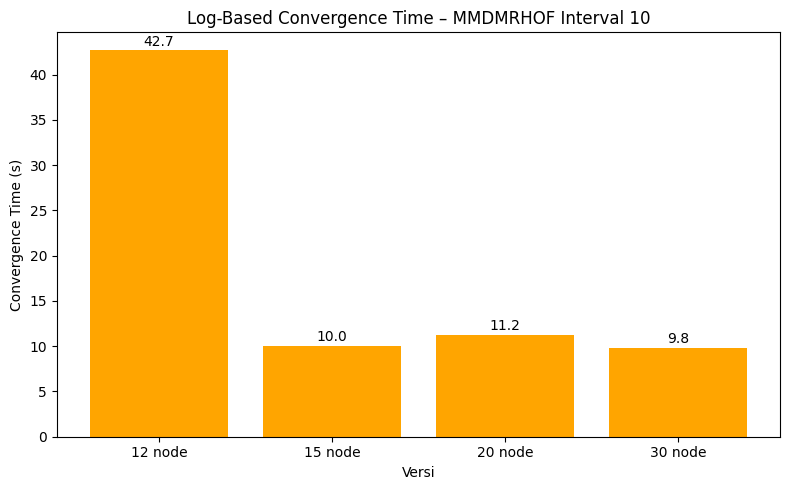

     Versi  Log-Based Convergence Time (s)
0  12 node                           42.66
1  15 node                           10.03
2  20 node                           11.23
3  30 node                            9.79


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# === STEP 1: Daftar file versi ===
file_paths = {
 "12 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/12node20.csv",
    "15 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/15node20.csv",
    "20 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/20node20.csv",
      "30 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/30node20.csv",
}

# === STEP 2: Regex untuk ambil jumlah ticks ===
pattern = re.compile(r"Convergence complete at (\d+) ticks")

# === STEP 3: Ekstraksi waktu konvergensi dari setiap file ===
convergence_times = {}

for version, path in file_paths.items():
    df = pd.read_csv(path)
    matched_row = df[df['message'].str.contains("Convergence complete at", na=False)]
    if not matched_row.empty:
        message = matched_row.iloc[0]['message']
        match = pattern.search(message)
        if match:
            ticks = int(match.group(1))
            convergence_times[version] = ticks * 0.01  # konversi ke detik (1 tick = 10 ms)
        else:
            convergence_times[version] = None
    else:
        convergence_times[version] = None

# === STEP 4: Buat DataFrame hasil ===
df_conv = pd.DataFrame({
    "Versi": list(convergence_times.keys()),
    "Log-Based Convergence Time (s)": list(convergence_times.values())
})

# === STEP 5: Visualisasi ===
plt.figure(figsize=(8, 5))
bars = plt.bar(df_conv["Versi"], df_conv["Log-Based Convergence Time (s)"], color='orange')

# Tambahkan label di atas batang
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.2, f'{yval:.1f}', ha='center', va='bottom')

plt.title("Log-Based Convergence Time – MMDMRHOF Interval 10")
plt.xlabel("Versi")
plt.ylabel("Convergence Time (s)")
plt.ylim(0, max(df_conv["Log-Based Convergence Time (s)"]) + 2)
plt.tight_layout()
plt.show()

# (Opsional) tampilkan tabel hasil
print(df_conv)


Signal Noise to Ratio (SNR)

[INFO] Sampel awal: 1481 | Dibuang (threshold): 23 | Dibuang (IQR): 39
Rata-rata SNR per Versi (dB) — setelah filter:


,Versi,SNR (dB)
0,12 node,7.995575
1,15 node,22.822581
2,20 node,24.103926
3,30 node,21.395556


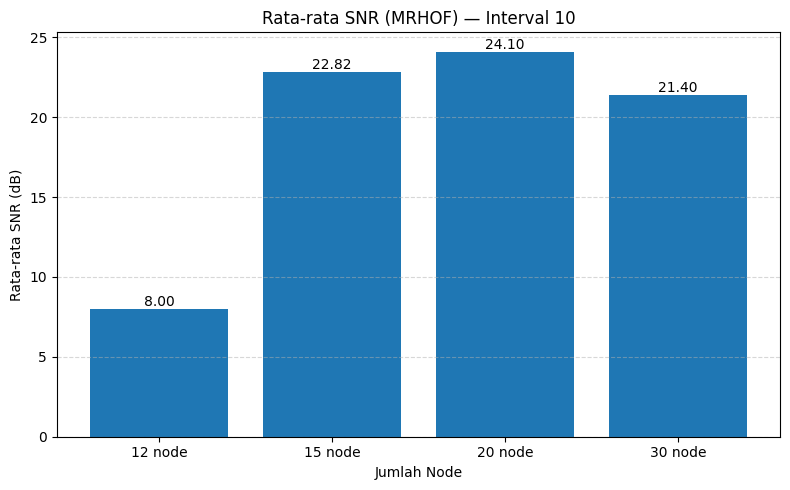

CSV tersimpan di: /content/snr_mrhof_output


In [ ]:
# === MRHOF SNR Parser & Plot (Mean only, Outlier Handling) ===
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# 1) Path CSV per skenario (sesuaikan)
file_paths = {
   "12 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/12node20.csv",
    "15 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/15node20.csv",
    "20 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/20node20.csv",
      "30 node": "/content/drive/MyDrive/LOG CONTIKI-NG/LOG 30 Agustus/CSV/MRHOF Percobaan 2/MRHOF 20/30node20.csv",
}

# 2) Regex SNR=... dB (angka bisa float, +/−)
snr_pattern = re.compile(r"SNR\s*=\s*(-?\d+(?:\.\d+)?)\s*dB", flags=re.IGNORECASE)

# === Parameter outlier ===
# Rentang fisik wajar untuk SNR link radio simulasi umumnya 0–60 dB (sesuaikan jika perlu).
LOWER_SNR_DB  = 0.0
UPPER_SNR_DB  = 80.0
USE_IQR = True  # filter tambahan berbasis IQR per versi

# 3) Ekstraksi SNR mentah
rows = []
for versi, path in file_paths.items():
    if not path or not Path(path).exists():
        print(f"[LEWATI] File tidak ditemukan: {path}")
        continue

    df = pd.read_csv(path)
    msg_col = "message" if "message" in df.columns else df.columns[-1]

    for _, r in df.iterrows():
        msg = str(r.get(msg_col, ""))
        m = snr_pattern.search(msg)
        if m:
            snr_val = float(m.group(1))
            rows.append({"Versi": versi, "SNR (dB)": snr_val})

df_snr_raw = pd.DataFrame(rows)
if df_snr_raw.empty:
    raise ValueError("Tidak ditemukan log 'SNR=... dB' pada file-file yang diberikan.")

# 4) Buang outlier (threshold + IQR per versi)
# Threshold fisik
df_snr = df_snr_raw[(df_snr_raw["SNR (dB)"] >= LOWER_SNR_DB) &
                    (df_snr_raw["SNR (dB)"] <= UPPER_SNR_DB)].copy()

removed_thresh = len(df_snr_raw) - len(df_snr)

# IQR per versi (opsional)
removed_iqr = 0
if USE_IQR and not df_snr.empty:
    cleaned = []
    for versi, g in df_snr.groupby("Versi"):
        Q1 = g["SNR (dB)"].quantile(0.25)
        Q3 = g["SNR (dB)"].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        cg = g[(g["SNR (dB)"] >= lower) & (g["SNR (dB)"] <= upper)]
        removed_iqr += len(g) - len(cg)
        cleaned.append(cg)
    df_snr = pd.concat(cleaned, ignore_index=True)

print(f"[INFO] Sampel awal: {len(df_snr_raw)} | Dibuang (threshold): {removed_thresh} | Dibuang (IQR): {removed_iqr}")
if df_snr.empty:
    raise ValueError("Semua data SNR terfilter. Sesuaikan batas threshold/IQR.")

# 5) Rata-rata SNR per Versi
avg_snr_per_versi = (
    df_snr.groupby("Versi", as_index=False)["SNR (dB)"].mean().sort_values("Versi")
)

print("Rata-rata SNR per Versi (dB) — setelah filter:")
display(avg_snr_per_versi)

# 6) Visualisasi: Bar chart mean SNR
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_snr_per_versi["Versi"], avg_snr_per_versi["SNR (dB)"])

for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h, f"{h:.2f}", ha="center", va="bottom")

plt.xlabel("Jumlah Node")
plt.ylabel("Rata-rata SNR (dB)")
plt.title("Rata-rata SNR (MRHOF) — Interval 10")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 7) Simpan CSV (opsional)
out_dir = Path("./snr_mrhof_output")
out_dir.mkdir(parents=True, exist_ok=True)
avg_snr_per_versi.to_csv(out_dir / "snr_summary_mean_filtered.csv", index=False)
print(f"CSV tersimpan di: {out_dir.resolve()}")
